# Group C – Decision Trees
## Can we identify a penguin's species from its measurements?

**The question:** can a computer learn simple yes/no rules that tell penguin species apart?

**The data:** the *Palmer Penguins* dataset, which has real measurements of penguins from Antarctica. There are three species: **Adelie**, **Chinstrap** and **Gentoo**. For each penguin I use four numbers:

* **Bill length:** how long its beak is, in mm
* **Bill depth:** how tall its beak is, in mm
* **Flipper length:** how long its wing is, in mm
* **Body mass:** how heavy it is, in grams

**What I will do:**
1. Look at the data
2. Learn how a decision tree works
3. Keep some penguins aside for testing
4. Decide how big the tree should be
5. Build the tree and read it
6. Test it on new penguins
7. Identify some new penguins

In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Make every chart clean and easy to read
plt.rcParams.update({"figure.figsize": (8, 5), "font.size": 12, "axes.grid": True, "grid.color": "#e6e5e0",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})
COLOURS = {"Adelie": "#2a78d6", "Chinstrap": "#eb6834", "Gentoo": "#1baf7a"}

### Step 1: Look at the data
I load the penguins and remove the 11 that have missing measurements. Then I count each species.

In [2]:
penguins = pd.read_csv("data/penguins.csv").dropna()
measurements = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

print("Number of penguins:", len(penguins))
print(penguins["species"].value_counts())
penguins[["species"] + measurements].head()

Number of penguins: 333
species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64


,species,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,Adelie,39.1,18.7,181.0,3750.0
1,Adelie,39.5,17.4,186.0,3800.0
2,Adelie,40.3,18.0,195.0,3250.0
4,Adelie,36.7,19.3,193.0,3450.0
5,Adelie,39.3,20.6,190.0,3650.0


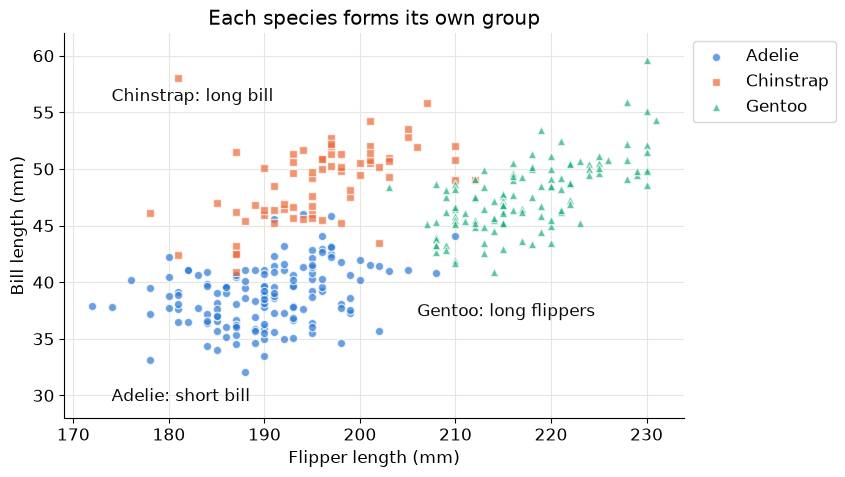

In [3]:
for species, marker in [("Adelie", "o"), ("Chinstrap", "s"), ("Gentoo", "^")]:
    group = penguins[penguins["species"] == species]
    plt.scatter(group["flipper_length_mm"], group["bill_length_mm"], color=COLOURS[species], marker=marker,
                alpha=0.7, edgecolor="white", label=species)

plt.text(174, 29.5, "Adelie: short bill", color="#0b0b0b")
plt.text(174, 56, "Chinstrap: long bill", color="#0b0b0b")
plt.text(206, 37, "Gentoo: long flippers", color="#0b0b0b")
plt.ylim(28, 62)
plt.xlabel("Flipper length (mm)")
plt.ylabel("Bill length (mm)")
plt.title("Each species forms its own group")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

**What the chart shows:** each mark is one penguin. **Gentoos** have much longer flippers than the others. **Adelies** and
**Chinstraps** have similar flippers, but Chinstraps have longer bills. We will see if the computer finds these rules without being told.

### Step 2: How does a decision tree work?
A decision tree is a flowchart of yes/no questions, like the game *20 Questions*. For example: "Is the flipper shorter than 207 mm?"

To build the tree, the computer does this:
1. Tries every measurement and every possible cut-off number
2. Picks the question that best separates the species, so each group has mostly one species. A group of only one species is called **pure**. The computer measures this with a score called **Gini impurity**, which is 0 for a pure group.
3. Repeats this for each new group, until the groups are pure or it reaches a limit I set

To identify a new penguin, it starts at the top and follows the answers down to a final box, called a **leaf**. The most common species in that leaf is the guess.

### Step 3: Keep some penguins aside for testing
A student who has seen the exam answers will score well, but that doesn't prove they understand the subject.
So I split the penguins into two groups:

* **Practice penguins (75%):** the tree learns from these
* **Test penguins (25%):** kept hidden, to check how well it handles new penguins

In [4]:
X = penguins[measurements]
y = penguins["species"]

X_practice, X_test, y_practice, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

print("Practice penguins:", len(X_practice))
print("Test penguins:", len(X_test))

Practice penguins: 249
Test penguins: 84


`stratify=y` keeps the same mix of species in both groups.

### Step 4: How big should the tree be?
**Depth** is the number of questions the tree can ask in a row. If I set no limit, it keeps adding questions until it gets every practice penguin right.

I compare different depths using two scores:
* **Practice score:** how many practice penguins it gets right
* **Check score:** a fairer score from **cross-validation**. I split the practice penguins into 5 parts, let each part take a turn as a mini test, and average the results.

In [5]:
rows = []
for depth in [1, 2, 3, 4, 5, None]:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    check_score = cross_val_score(tree, X_practice, y_practice, cv=5).mean()
    tree.fit(X_practice, y_practice)
    rows.append({"Depth": depth or "No limit",
                 "Leaves": tree.get_n_leaves(),
                 "Practice score": f"{tree.score(X_practice, y_practice):.1%}",
                 "Check score": f"{check_score:.1%}"})

pd.DataFrame(rows).set_index("Depth")

,Leaves,Practice score,Check score
Depth,,,
1,2,78.7%,78.7%
2,4,96.4%,95.2%
3,7,97.2%,95.2%
4,10,99.6%,96.8%
5,11,100.0%,96.0%
No limit,11,100.0%,96.0%


**What this shows:** a **leaf** is a final box in the tree, so more leaves means more rules.
* **Depth 1** can only ask one question, which isn't enough to separate three species. This is **underfitting**.
* **No limit** gets 100% of the practice penguins right, but its check score falls from 96.8% at depth 4 to 96.0%. It is adding rules just for a few unusual penguins. This is **overfitting**.
* **Depth 4** has the best check score, but it needs 10 leaves.
* **Depths 2 and 3** tie on the check score at 95.2%, and depth 3 gets slightly more practice penguins right.

**My choice is depth 3.** It gives up about 1.6% of the check score for a tree with only 7 leaves, which is small enough to read and explain.

### Step 5: Build the tree and read it
Start at the top box and follow the arrows. Go **left if the answer is True** and **right if it is False**. Each box shows:

* The **question** (the leaves have no question, because they are the final boxes)
* **samples:** how many practice penguins reached this box
* **value:** how many of those are Adelie, Chinstrap and Gentoo, in that order
* **class:** the most common species in the box, which also sets its colour

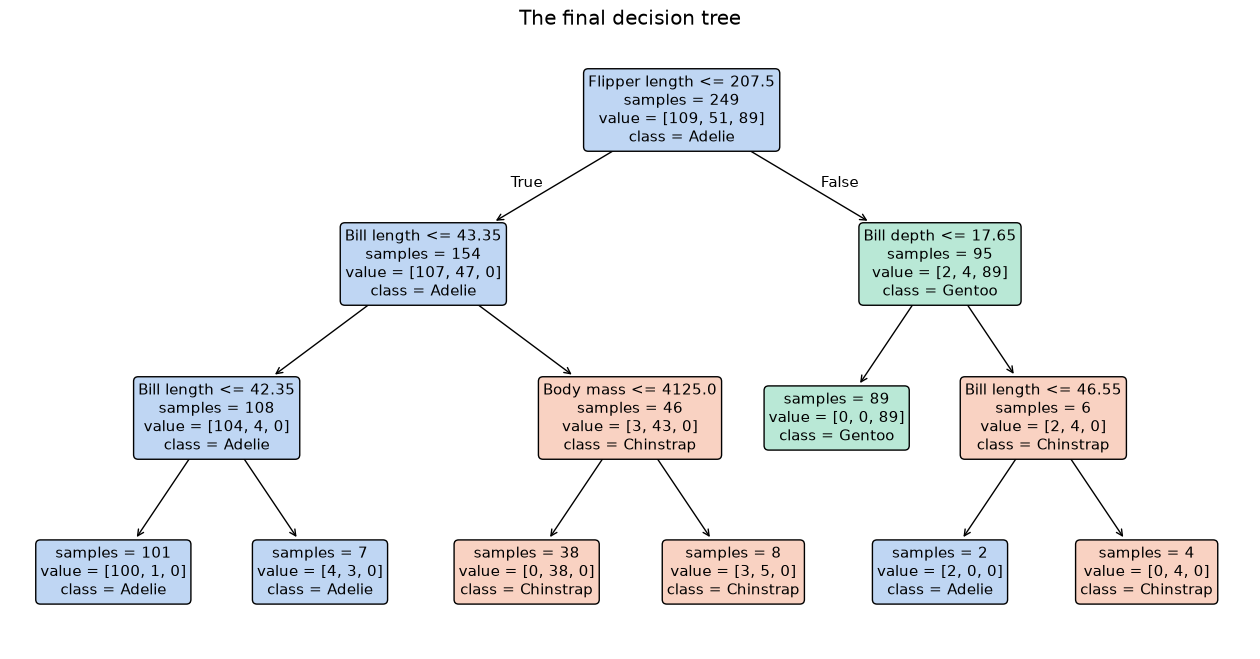

In [6]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_practice, y_practice)

PALE_COLOURS = {"Adelie": "#bfd6f3", "Chinstrap": "#f9d2c2", "Gentoo": "#b9e8d6"}

plt.figure(figsize=(16, 8))
boxes = plot_tree(tree, feature_names=["Bill length", "Bill depth", "Flipper length", "Body mass"],
                  class_names=list(tree.classes_), impurity=False, rounded=True, fontsize=11)

for box in boxes:                                             # colour each box by its most common species
    if "class = " in box.get_text():
        species = box.get_text().split("class = ")[-1].strip()
        box.get_bbox_patch().set_facecolor(PALE_COLOURS[species])

plt.title("The final decision tree")
plt.show()

**The main rules in plain English:**
1. **Is the flipper 207.5 mm or less?** This comes first because it separates a whole species. All 89 practice Gentoos go right.
2. **If the flipper is short, is the bill 43.35 mm or shorter?** Shorter bills are mostly Adelie, and longer bills are mostly Chinstrap.
3. **If the flipper is long, is the bill depth 17.65 mm or less?** If yes, it is a Gentoo. If no, it is one of a few large Adelies or Chinstraps.

Nobody told the tree these rules. It found the same patterns we saw in the first chart.

The bottom row only fine-tunes the groups. Some splits give the same species on both sides, because they make the groups purer without changing the guess.

### Step 6: Test it on new penguins
Now I check the tree on the test penguins, which it has never seen. The table shows the real species in each row and the tree's guess in each column.

In [7]:
guesses = tree.predict(X_test)

print(f"Correct on test penguins: {tree.score(X_test, y_test):.1%}")
pd.crosstab(y_test, guesses, rownames=["Real species"], colnames=["Tree's guess"])

Correct on test penguins: 95.2%


Tree's guess,Adelie,Chinstrap,Gentoo
Real species,,,
Adelie,36,1,0
Chinstrap,1,16,0
Gentoo,0,2,28


**What this shows:** the tree gets 80 of the 84 test penguins right, which is about 95%. There are 4 mistakes:
* 1 Adelie was guessed as a Chinstrap
* 1 Chinstrap was guessed as an Adelie
* 2 Gentoos were guessed as Chinstraps

### Step 7: Identify some new penguins
I give the tree three made-up penguins and ask it to identify them.

In [8]:
new_penguins = pd.DataFrame([
    [39.0, 18.5, 190, 3700],
    [47.0, 15.0, 217, 5000],
    [50.0, 19.0, 196, 3800],
], columns=measurements)

new_penguins["guess"] = tree.predict(new_penguins[measurements])
new_penguins

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,guess
0,39.0,18.5,190,3700,Adelie
1,47.0,15.0,217,5000,Gentoo
2,50.0,19.0,196,3800,Chinstrap


**Following the tree by hand for the second penguin:**
1. Is the flipper 207.5 mm or less? It is 217 mm, so **no**, and we go right.
2. Is the bill depth 17.65 mm or less? It is 15 mm, so **yes**, and we reach **Gentoo**.

This matches the tree's guess.

### Conclusion
* The decision tree learned **simple rules** that get about **95%** of new penguins right. It checks flipper length first, then bill length or bill depth.
* **Limiting the depth** stopped the tree from memorising unusual penguins, and kept it easy to explain.
* **Strengths:** anyone can read the rules, and the measurements don't need to be on the same scale, because each question looks at only one measurement.
* **Weakness:** a small change in the data can produce a different tree. A **Random Forest** deals with this by combining many trees.
* **Main lesson:** a simple model you can explain can do almost as well as a more complicated one.